# Statistical Analysis: Confirmation vs. Falsification Information-Seeking Across 2,000,000 LLM Conversations (`lmsys-chat-1m` & `WildChat-1M`)

This notebook conducts the statistical analysis and robustness checks across two independent 1-million-conversation datasets:
1. **`lmsys/lmsys-chat-1m` (1,000,000 conversations):** Pooled Explicit-Belief + GPU Semantic-Embedding funnels ($N = 1,922$ candidates $\rightarrow$ $N = 332$ Stage-3 queries).
2. **`allenai/WildChat-1M` (1,000,000 conversations):** Pooled Explicit-Belief + GPU Semantic-Embedding funnels ($N = 1,567$ candidates $\rightarrow$ $N = 123$ Stage-3 queries).
3. **Combined 2-Million-Conversation Corpus:** $N = 3,489$ unique candidates $\rightarrow$ $N = 1,631$ policy conversations $\rightarrow$ $N = 537$ prior-belief conversations $\rightarrow$ **$N = 455$ Stage-3 information-seeking queries**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(PROJECT_ROOT / 'src'))

from analyze import (
    load_deduped_jsonl_records,
    exact_binomial_test,
    wilson_ci,
    chisq_gof_uniform,
    contingency_chisq_permutation,
    build_text_clusters,
    cluster_bootstrap_ci,
    compute_fragility_and_max_deff,
    score_human_validation,
)

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
LMSYS_A = PROCESSED_DIR / 'classified_candidates_full_1m_belief_crossturn.jsonl'
LMSYS_B = PROCESSED_DIR / 'classified_candidates_full_1m_all_policy_sem1000.jsonl'
WILD_A = PROCESSED_DIR / 'classified_wildchat_candidates_full_1m_belief_crossturn.jsonl'
WILD_B = PROCESSED_DIR / 'classified_wildchat_candidates_full_1m_all_policy_sem1000.jsonl'

df_lmsys = load_deduped_jsonl_records([LMSYS_A, LMSYS_B])
df_wildchat = load_deduped_jsonl_records([WILD_A, WILD_B])
df_2m = load_deduped_jsonl_records([LMSYS_A, LMSYS_B, WILD_A, WILD_B])

print(f'LMSYS-Chat-1M unique classified    : {len(df_lmsys):,}')
print(f'WildChat-1M unique classified      : {len(df_wildchat):,}')
print(f'Total 2M Corpus unique classified  : {len(df_2m):,}')

LMSYS-Chat-1M unique classified    : 1,922
WildChat-1M unique classified      : 1,567
Total 2M Corpus unique classified  : 3,489


## 1. Hierarchical Classification Funnel Across Datasets

In [2]:
def summarize_funnel(df: pd.DataFrame, label: str) -> dict:
    n_tot = len(df)
    s1 = df[df['is_policy_or_political'] == True]
    s2 = s1[s1['user_states_prior_belief'] == True]
    s3 = s2[s2['seeking_type'].isin(['confirming', 'neutral', 'falsifying'])]
    return {
        'Dataset': label,
        'Candidates Classified': n_tot,
        'Stage 1: Policy Topic': f"{len(s1):,} ({len(s1)/n_tot:.1%})",
        'Stage 2: Prior Belief Stated': f"{len(s2):,} ({len(s2)/len(s1):.1%} of S1)",
        'Stage 3: Info-Seeking Query': f"{len(s3):,} ({len(s3)/len(s2):.1%} of S2)",
    }

pd.DataFrame([
    summarize_funnel(df_lmsys, 'LMSYS-Chat-1M (1M Raw)'),
    summarize_funnel(df_wildchat, 'WildChat-1M (1M Raw)'),
    summarize_funnel(df_2m, 'Combined 2M Corpus (2M Raw)'),
])

,Dataset,Candidates Classified,Stage 1: Policy Topic,Stage 2: Prior Belief Stated,Stage 3: Info-Seeking Query
0,LMSYS-Chat-1M (1M Raw),1922,966 (50.3%),387 (40.1% of S1),332 (85.8% of S2)
1,WildChat-1M (1M Raw),1567,665 (42.4%),150 (22.6% of S1),123 (82.0% of S2)
2,Combined 2M Corpus (2M Raw),3489,"1,631 (46.7%)",537 (32.9% of S1),455 (84.7% of S2)


## 2. Stage 3 Prevalence Breakdown (`confirming` vs. `neutral` vs. `falsifying`)

In [3]:
def prevalence_table(df: pd.DataFrame) -> pd.DataFrame:
    s3 = df[(df['is_policy_or_political'] == True) & (df['user_states_prior_belief'] == True) & (df['seeking_type'].isin(['confirming', 'neutral', 'falsifying']))]
    n = len(s3)
    rows = []
    for cat in ['confirming', 'neutral', 'falsifying']:
        k = int((s3['seeking_type'] == cat).sum())
        lo, hi = wilson_ci(k, n)
        rows.append({
            'seeking_type': cat,
            'count': k,
            'total_stage3': n,
            'share_pct': round(100 * k / n, 1),
            'wilson_95_ci': f'[{100*lo:.1f}%, {100*hi:.1f}%]',
        })
    return pd.DataFrame(rows)

print('=== Combined 2M Corpus (N = 455) ===')
display(prevalence_table(df_2m))

print('=== LMSYS-Chat-1M (N = 332) ===')
display(prevalence_table(df_lmsys))

print('=== WildChat-1M (N = 123) ===')
display(prevalence_table(df_wildchat))

=== Combined 2M Corpus (N = 455) ===
=== LMSYS-Chat-1M (N = 332) ===
=== WildChat-1M (N = 123) ===


,seeking_type,count,total_stage3,share_pct,wilson_95_ci
0,confirming,286,455,62.9,"[58.3%, 67.2%]"
1,neutral,129,455,28.4,"[24.4%, 32.7%]"
2,falsifying,40,455,8.8,"[6.5%, 11.8%]"


,seeking_type,count,total_stage3,share_pct,wilson_95_ci
0,confirming,221,332,66.6,"[61.3%, 71.4%]"
1,neutral,80,332,24.1,"[19.8%, 29.0%]"
2,falsifying,31,332,9.3,"[6.7%, 12.9%]"


,seeking_type,count,total_stage3,share_pct,wilson_95_ci
0,confirming,65,123,52.8,"[44.1%, 61.4%]"
1,neutral,49,123,39.8,"[31.6%, 48.7%]"
2,falsifying,9,123,7.3,"[3.9%, 13.3%]"


## 3. Cross-Dataset Replication of Primary & Secondary Hypothesis Tests

Notice the virtually identical directional confirmation preference across the two independent 1-million-conversation datasets:
- **`lmsys-chat-1m`:** **87.7%** confirming (`7.13x` ratio, $p = 7.91 \times 10^{-37}$)
- **`WildChat-1M`:** **87.8%** confirming (`7.22x` ratio, $p = 6.76 \times 10^{-12}$)
- **Combined 2M Corpus:** **87.7%** confirming (`7.15x` ratio, $p = 2.90 \times 10^{-47}$)

In [4]:
def run_hypothesis_tests(df: pd.DataFrame, label: str) -> dict:
    s3 = df[(df['is_policy_or_political'] == True) & (df['user_states_prior_belief'] == True) & (df['seeking_type'].isin(['confirming', 'neutral', 'falsifying']))]
    n_conf = int((s3['seeking_type'] == 'confirming').sum())
    n_neut = int((s3['seeking_type'] == 'neutral').sum())
    n_fals = int((s3['seeking_type'] == 'falsifying').sum())
    n_dir = n_conf + n_fals
    n_all = len(s3)

    lo_dir, hi_dir = wilson_ci(n_conf, n_dir)
    p_dir_1s, _ = exact_binomial_test(n_conf, n_dir, p=0.5)
    p_all_1s, _ = exact_binomial_test(n_conf, n_all, p=0.5)
    chi2_stat, chi2_p = chisq_gof_uniform([n_conf, n_neut, n_fals])

    return {
        'Dataset': label,
        'Directional (Conf vs Fals)': f'{n_conf} vs {n_fals} (N={n_dir})',
        'Confirming % (Directional)': f'{100*n_conf/n_dir:.1f}% [{100*lo_dir:.1f}%, {100*hi_dir:.1f}%]',
        'Confirm : Falsify Ratio': f'{n_conf/n_fals:.2f}x',
        'Binomial p (1-sided, Conf > Fals)': f'{p_dir_1s:.3e}',
        'Binomial p (Conf > Neut+Fals)': f'{p_all_1s:.3e}',
        'Multinomial Chi2 (df=2)': f'{chi2_stat:.2f} (p={chi2_p:.3g})',
    }

pd.DataFrame([
    run_hypothesis_tests(df_lmsys, 'LMSYS-Chat-1M'),
    run_hypothesis_tests(df_wildchat, 'WildChat-1M'),
    run_hypothesis_tests(df_2m, 'Combined 2M Corpus'),
])

,Dataset,Directional (Conf vs Fals),Confirming % (Directional),Confirm : Falsify Ratio,"Binomial p (1-sided, Conf > Fals)",Binomial p (Conf > Neut+Fals),Multinomial Chi2 (df=2)
0,LMSYS-Chat-1M,221 vs 31 (N=252),"87.7% [83.1%, 91.2%]",7.13x,7.905e-37,7.873e-10,175.85 (p=0)
1,WildChat-1M,65 vs 9 (N=74),"87.8% [78.5%, 93.5%]",7.22x,6.755e-12,2.943e-01,40.59 (p=0)
2,Combined 2M Corpus,286 vs 40 (N=326),"87.7% [83.7%, 90.9%]",7.15x,2.900e-47,2.285e-08,204.58 (p=0)


## 4. Subgroup Heterogeneity by Policy Topic Category (Combined 2M Corpus, $N = 455$)

In [5]:
s3_2m = df_2m[
    (df_2m['is_policy_or_political'] == True)
    & (df_2m['user_states_prior_belief'] == True)
    & (df_2m['seeking_type'].isin(['confirming', 'neutral', 'falsifying']))
].copy()

ct_counts = pd.crosstab(s3_2m['topic_category'], s3_2m['seeking_type'])[['confirming', 'neutral', 'falsifying']]
ct_pct = ct_counts.div(ct_counts.sum(axis=1), axis=0).mul(100).round(1)
ct_summary = ct_counts.astype(str) + ' (' + ct_pct.astype(str) + '%)'
ct_summary['Total'] = ct_counts.sum(axis=1)

chi2_ind, p_ind = contingency_chisq_permutation(ct_counts.values)
print(f'Topic x Seeking-Type Independence Test: Chi2 = {chi2_ind:.2f}, Permutation p = {p_ind:.4f}')
ct_summary

Topic x Seeking-Type Independence Test: Chi2 = 8.90, Permutation p = 0.0593


seeking_type,confirming,neutral,falsifying,Total
topic_category,,,,
economic_policy,36 (58.1%),23 (37.1%),3 (4.8%),62
politics,30 (60.0%),11 (22.0%),9 (18.0%),50
social_policy,220 (64.1%),95 (27.7%),28 (8.2%),343


## 5. Non-Independence & Unobserved User Clustering Robustness

In [6]:
def clustering_robustness_table(df: pd.DataFrame, label: str, sim_threshold: float = 0.65) -> dict:
    dir_df = df[
        (df['is_policy_or_political'] == True)
        & (df['user_states_prior_belief'] == True)
        & (df['seeking_type'].isin(['confirming', 'falsifying']))
    ].copy()
    n_conf = int((dir_df['seeking_type'] == 'confirming').sum())
    n_fals = int((dir_df['seeking_type'] == 'falsifying').sum())

    texts = (dir_df['stated_belief_summary'].fillna('') + ' ' + dir_df['information_seeking_quote'].fillna('')).tolist()
    clusters = build_text_clusters(texts, sim_threshold=sim_threshold)
    dir_df['cluster_id'] = clusters
    n_clusters = len(np.unique(clusters))

    is_conf = (dir_df['seeking_type'] == 'confirming').astype(int).to_numpy()
    boot_se, boot_lo, boot_hi = cluster_bootstrap_ci(is_conf, clusters)

    dedup_df = dir_df.groupby('cluster_id', as_index=False).first()
    c_dedup = int((dedup_df['seeking_type'] == 'confirming').sum())
    f_dedup = int((dedup_df['seeking_type'] == 'falsifying').sum())
    p_dedup_1s, _ = exact_binomial_test(c_dedup, c_dedup + f_dedup, p=0.5)

    fragility, max_deff = compute_fragility_and_max_deff(n_conf, n_fals)

    return {
        'Dataset': label,
        'Independent Clusters': f'{n_clusters} / {len(dir_df)}',
        'Cluster-Bootstrap 95% CI': f'[{100*boot_lo:.1f}%, {100*boot_hi:.1f}%] (SE={boot_se:.3f})',
        '1-Per-Cluster Count': f'{c_dedup} vs {f_dedup} ({100*c_dedup/(c_dedup+f_dedup):.1f}%)',
        '1-Per-Cluster Binomial p': f'{p_dedup_1s:.3e}',
        'Fragility Index (alpha=.05)': f'{fragility} / {n_conf} ({100*fragility/n_conf:.1f}%)',
        'Max Tolerable DEFF': f'{max_deff:.2f}x',
    }

pd.DataFrame([
    clustering_robustness_table(df_lmsys, 'LMSYS-Chat-1M'),
    clustering_robustness_table(df_wildchat, 'WildChat-1M'),
    clustering_robustness_table(df_2m, 'Combined 2M Corpus'),
])

,Dataset,Independent Clusters,Cluster-Bootstrap 95% CI,1-Per-Cluster Count,1-Per-Cluster Binomial p,Fragility Index (alpha=.05),Max Tolerable DEFF
0,LMSYS-Chat-1M,248 / 252,"[83.6%, 91.6%] (SE=0.021)",217 vs 31 (87.5%),7.479e-36,174 / 221 (78.7%),52.95x
1,WildChat-1M,74 / 74,"[79.7%, 94.6%] (SE=0.038)",65 vs 9 (87.8%),6.755e-12,46 / 65 (70.8%),15.66x
2,Combined 2M Corpus,322 / 326,"[84.0%, 91.1%] (SE=0.018)",282 vs 40 (87.6%),2.747e-46,228 / 286 (79.7%),68.61x


## 6. Inspect Sample Classified Conversations ($N = 455$) & Score Human Validation

In [7]:
stage3_csv = pd.read_csv(PROCESSED_DIR / 'stage3_seeking_conversations_455.csv')
cols = ['seeking_type', 'topic_category', 'stated_belief_summary', 'information_seeking_quote']

print('--- Sample CONFIRMING Queries ---')
display(stage3_csv[stage3_csv['seeking_type'] == 'confirming'][cols].head(5))

print('--- Sample FALSIFYING Queries ---')
display(stage3_csv[stage3_csv['seeking_type'] == 'falsifying'][cols].head(5))

print('--- Sample NEUTRAL Queries ---')
display(stage3_csv[stage3_csv['seeking_type'] == 'neutral'][cols].head(5))

--- Sample CONFIRMING Queries ---
--- Sample FALSIFYING Queries ---
--- Sample NEUTRAL Queries ---


,seeking_type,topic_category,stated_belief_summary,information_seeking_quote
0,confirming,economic_policy,The user believes that Universal Basic Income (UBI) is a 'stillborn idea' and contradicts the concepts of a Resource Based Economy and community-led projects.,"imho UBI is stillborn idea (and contradicts with other mentioned points), but for other reasons than common criticism rises (think out of the box to guess why)."
1,confirming,economic_policy,"The user believes that Intel's high pricing and potential monopoly status exacerbate income inequality, whereas AMD provides more value to the world by offering competition and more affordable processors. They also believe corporate sustainability efforts are often a 'scam' for profit and that AMD is more socially responsible because it prioritizes reaching more people over maximizing profit.",Therefore because amd does not overcharge we can see that they are less likely to take advantage of the situation by harming people who have less income. Furthermore this is evidence that by being the only competition for Intel in the pc processor market amd has more value to the world.
2,confirming,economic_policy,The user believes that regulations are primarily tools used by large corporations to stifle competition and that startups should remain unregulated to preserve the entrepreneurial mindset.,Isn't regulation a thing that only big corporations want to save themselves and eradicate competition?
3,confirming,economic_policy,"The user believes that government intervention in private corporate activities, such as pipeline construction, constitutes an infringement on private corporations.",Doesn't this infringe on government interfering with private corporations?
4,confirming,economic_policy,The user believes that an inverted yield curve historically precedes a recession.,Do you think there is a high chance for a recession in this scenario?


,seeking_type,topic_category,stated_belief_summary,information_seeking_quote
286,falsifying,economic_policy,The user believes that approval voting is the best method and suggests that a world war is necessary to implement it.,Well than how can we change the voting method without war?
287,falsifying,economic_policy,The user believes that a society where megacorporations own all non-government property and people must rent homes is a form of feudalism.,How is this not a form of feudalism?
288,falsifying,economic_policy,"The user believes that the US government's financial planning is ineffective and lacks careful planning, evidenced by budget deficits, high debt levels, and the inverted yield curve. They also suggest that the 'financial catastrophe' narrative was a result of poor planning rather than an unpredictable crisis, and they argue that Japan's debt model might be superior to the US's.","I consider that the careful planning is in place. So, it means, that debt cell increase was planned in time, when it’s happened. So, there was no any urgency or risk for the world economy... How should we put it in some logic?"
289,falsifying,politics,The user believes the politician (NAME_1) is a corrupt individual and that corruption and economic destruction are undemocratic.,"well, name me one good thing he has done in his career as a politician."
290,falsifying,politics,The user believes the war in Ukraine has lasted too long and is exacerbated by government unwillingness to seek peace and 'malicious interference' by warmongers; they also view the 'bad precedent' argument as a fallacy.,Please list some counter arguments to my position.


,seeking_type,topic_category,stated_belief_summary,information_seeking_quote
326,neutral,economic_policy,"The user is asking for two specific models (optimistic and skeptical) regarding the reduction of fossil fuel consumption, implying a recognition of the uncertainty and the need for contrasting viewpoints on the trajectory of energy policy.",can you run 2 models one optimistic and one skeptical model regarding reducing of usage of fossil fuels where you can provide some more or less tangible figures
327,neutral,economic_policy,"The user believes the AI will be unable to find them a job in China, but they acknowledge and observe the significant presence of Chinese people and companies involved in large-scale projects in Israel.",I believe that you will not be able to find me a job in china but maybe you know something about the biliteral relationship between israel and chaina? I know that a lot of chainees poeple are working here in israel and chainees companies are building big projects here. what do you know about it?
328,neutral,economic_policy,The user believes that wealthy individuals evade taxes through trusts and foundations and that government corruption caused by lobbying prevents the implementation of laws that would disadvantage the wealthy.,do you think Europe is better than the US in implementing social measures?
329,neutral,economic_policy,"The user believes that if someone willingly takes a risk that results in harm, they are responsible for their own suffering.",Does that mean I agree or disagree with this proverb?
330,neutral,economic_policy,The user believes in 'fair trade' over 'free trade' because free trade hurts small businesses and benefits large corporations. They believe nations should not trade with hostile nations and that domestic industry should be balanced with foreign industry.,Which options should I go for?


In [8]:
# Score Human Inter-Rater Reliability (Cohen's kappa) once human_validation_blind_sample_60.csv is filled in
blind_path = PROCESSED_DIR / 'human_validation_blind_sample_60.csv'
key_path = PROCESSED_DIR / 'human_validation_answer_key_60.csv'
print(score_human_validation(blind_path, key_path))

No human labels filled in yet.


## 7. Publication Figure: 3-Panel Composite (`Figure 1`)

- **Panel A:** 3-Way Information-Seeking Distribution (`Confirming`, `Neutral`, `Falsifying`) with 95% Wilson CIs across `LMSYS-Chat-1M`, `WildChat-1M`, and the `Combined 2M Corpus`.
- **Panel B:** Forest Plot of Directional Confirmation Share ($p_{\text{confirm}}$) and 95% CIs across datasets, retrieval funnels, and semantic clustering vs. the 50% equal-preference benchmark.
- **Panel C:** Information-Seeking Distribution across Policy Domains (`Social Policy`, `Economic Policy`, `Politics`).

Saves 300-DPI `.png` and vector `.pdf` to `data/processed/figure1_confirmation_bias_2m.{png,pdf}`.

Saved high-res figures to:
  - C:\Users\cmck\confirmationBias\data\processed\figure1_confirmation_bias_2m.png
  - C:\Users\cmck\confirmationBias\data\processed\figure1_confirmation_bias_2m.pdf


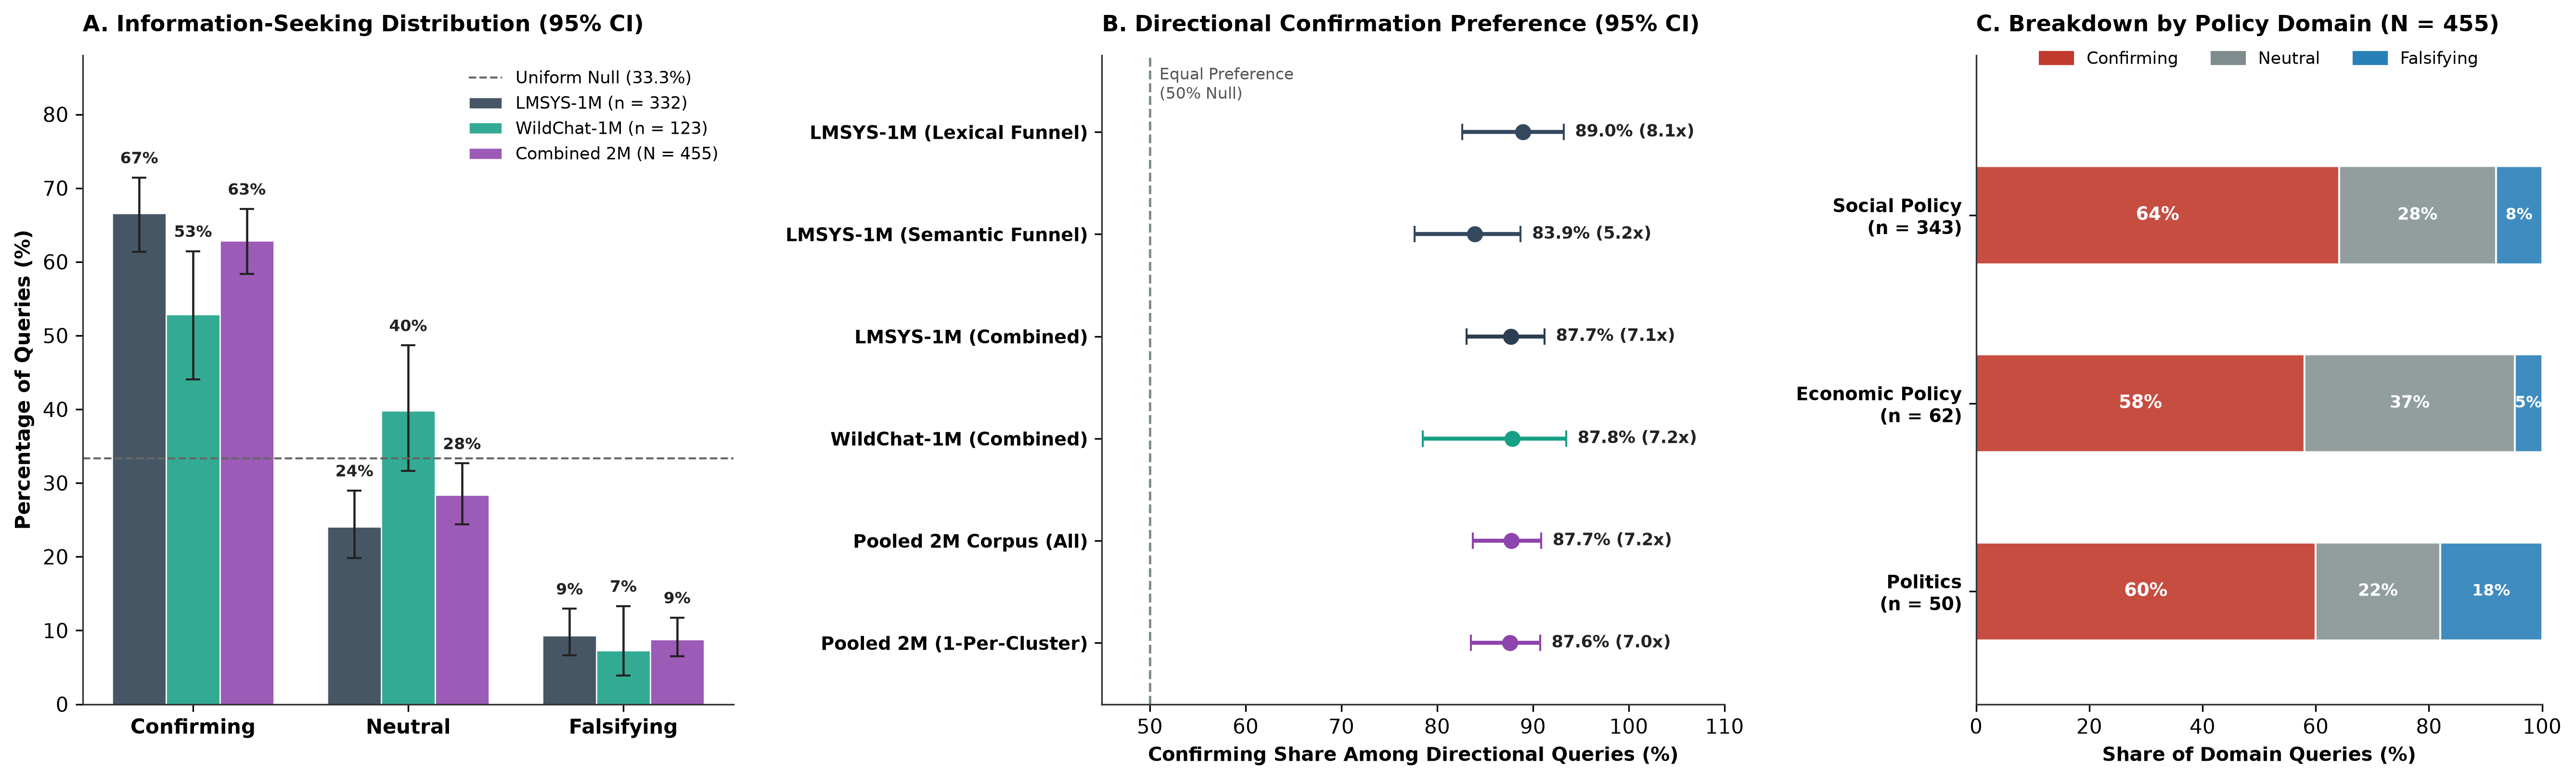

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

fig, (ax_a, ax_b, ax_c) = plt.subplots(
    1, 3, figsize=(18.0, 5.4), dpi=150,
     layout='constrained', gridspec_kw={'width_ratios': [1.15, 1.1, 1.0]}
)
fig.get_layout_engine().set(w_pad=0.18, h_pad=0.1)

# Colorblind-safe academic palette
C_CONF = '#C0392B'   # Deep Crimson for Confirming
C_NEUT = '#7F8C8D'   # Slate Gray for Neutral
C_FALS = '#2980B9'   # Steel Blue for Falsifying

# -------------------------------------------------------------------------
# PANEL A: 3-Way Prevalence Grouped Bar Chart with 95% Wilson CIs
# -------------------------------------------------------------------------
datasets_a = [
    ('LMSYS-1M (n = 332)', df_lmsys, '#2C3E50'),
    ('WildChat-1M (n = 123)', df_wildchat, '#16A085'),
    ('Combined 2M (N = 455)', df_2m, '#8E44AD'),
]
categories = ['confirming', 'neutral', 'falsifying']
cat_labels = ['Confirming', 'Neutral', 'Falsifying']
x = np.arange(len(categories))
width = 0.25

for i, (d_label, d_df, color) in enumerate(datasets_a):
    s3 = d_df[(d_df['is_policy_or_political'] == True) & (d_df['user_states_prior_belief'] == True) & (d_df['seeking_type'].isin(categories))]
    n = len(s3)
    pcts, err_lo, err_hi = [], [], []
    for cat in categories:
        k = int((s3['seeking_type'] == cat).sum())
        p = 100.0 * k / n
        lo, hi = wilson_ci(k, n)
        pcts.append(p)
        err_lo.append(p - 100.0 * lo)
        err_hi.append(100.0 * hi - p)
    offset = (i - 1) * width
    bars = ax_a.bar(
        x + offset, pcts, width, label=d_label,
        color=color, alpha=0.88, edgecolor='white', linewidth=0.7,
        yerr=[err_lo, err_hi], capsize=3.5, error_kw={'elinewidth': 1.1, 'ecolor': '#222222'}
    )
    for bar, p, eh in zip(bars, pcts, err_hi):
        ax_a.text(
            bar.get_x() + bar.get_width() / 2, p + eh + 1.4,
            f'{p:.0f}%', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#222222'
        )

ax_a.axhline(33.33, color='#666666', linestyle='--', linewidth=1.0, label='Uniform Null (33.3%)')
ax_a.set_xticks(x)
ax_a.set_xticklabels(cat_labels, fontsize=10, fontweight='bold')
ax_a.set_ylabel('Percentage of Queries (%)', fontsize=10, fontweight='bold')
ax_a.set_ylim(0, 88)
ax_a.set_title('A. Information-Seeking Distribution (95% CI)', fontsize=11, fontweight='bold', loc='left', pad=12)
ax_a.legend(frameon=False, fontsize=8.3, loc='upper right')
ax_a.spines['top'].set_visible(False)
ax_a.spines['right'].set_visible(False)

# -------------------------------------------------------------------------
# PANEL B: Directional Confirmation Forest Plot across Datasets & Funnels
# -------------------------------------------------------------------------
df_lmsys_a = load_deduped_jsonl_records([LMSYS_A])
df_lmsys_b = load_deduped_jsonl_records([LMSYS_B])

dir_2m = df_2m[(df_2m['is_policy_or_political'] == True) & (df_2m['user_states_prior_belief'] == True) & (df_2m['seeking_type'].isin(['confirming', 'falsifying']))].copy()
texts_2m = (dir_2m['stated_belief_summary'].fillna('') + ' ' + dir_2m['information_seeking_quote'].fillna('')).tolist()
dir_2m['cluster_id'] = build_text_clusters(texts_2m, sim_threshold=0.65)
dedup_2m = dir_2m.groupby('cluster_id', as_index=False).first()

forest_specs = [
    ('Pooled 2M (1-Per-Cluster)', dedup_2m, '#8E44AD'),
    ('Pooled 2M Corpus (All)', df_2m, '#8E44AD'),
    ('WildChat-1M (Combined)', df_wildchat, '#16A085'),
    ('LMSYS-1M (Combined)', df_lmsys, '#2C3E50'),
    ('LMSYS-1M (Semantic Funnel)', df_lmsys_b, '#34495E'),
    ('LMSYS-1M (Lexical Funnel)', df_lmsys_a, '#34495E'),
]

y_pos = np.arange(len(forest_specs))
ax_b.axvline(50.0, color='#7F8C8D', linestyle='--', linewidth=1.2, zorder=1)
ax_b.text(51.0, len(forest_specs) - 0.35, 'Equal Preference\n(50% Null)', fontsize=8, color='#555555', va='top')

for idx, (f_label, f_df, f_color) in enumerate(forest_specs):
    d_sub = f_df[(f_df['is_policy_or_political'] == True) & (f_df['user_states_prior_belief'] == True) & (f_df['seeking_type'].isin(['confirming', 'falsifying']))]
    c = int((d_sub['seeking_type'] == 'confirming').sum())
    f = int((d_sub['seeking_type'] == 'falsifying').sum())
    n_d = c + f
    p = 100.0 * c / n_d
    lo, hi = wilson_ci(c, n_d)
    lo_p, hi_p = 100.0 * lo, 100.0 * hi
    ratio = c / f

    ax_b.errorbar(
        p, idx, xerr=[[p - lo_p], [hi_p - p]], fmt='o', color=f_color,
        ecolor=f_color, elinewidth=2.0, capsize=4, markersize=7, zorder=3
    )
    ax_b.text(
        hi_p + 1.2, idx, f'{p:.1f}% ({ratio:.1f}x)',
        va='center', ha='left', fontsize=8.3, fontweight='bold', color='#222222'
    )

ax_b.set_yticks(y_pos)
ax_b.set_yticklabels([s[0] for s in forest_specs], fontsize=9, fontweight='bold')
ax_b.set_xlabel('Confirming Share Among Directional Queries (%)', fontsize=9.5, fontweight='bold')
ax_b.set_xlim(45, 110)
ax_b.set_ylim(-0.6, len(forest_specs) - 0.25)
ax_b.set_title('B. Directional Confirmation Preference (95% CI)', fontsize=11, fontweight='bold', loc='left', pad=12)
ax_b.spines['top'].set_visible(False)
ax_b.spines['right'].set_visible(False)

# -------------------------------------------------------------------------
# PANEL C: 100% Horizontal Stacked Bar by Policy Domain (2M Pooled)
# -------------------------------------------------------------------------
s3_all = df_2m[(df_2m['is_policy_or_political'] == True) & (df_2m['user_states_prior_belief'] == True) & (df_2m['seeking_type'].isin(categories))]
domain_order = [
    ('politics', 'Politics\n(n = 50)'),
    ('economic_policy', 'Economic Policy\n(n = 62)'),
    ('social_policy', 'Social Policy\n(n = 343)'),
]
y_dom = np.arange(len(domain_order))
bar_h = 0.52

for idx, (dom_key, dom_label) in enumerate(domain_order):
    sub = s3_all[s3_all['topic_category'] == dom_key]
    tot = len(sub)
    p_c = 100.0 * (sub['seeking_type'] == 'confirming').sum() / tot
    p_n = 100.0 * (sub['seeking_type'] == 'neutral').sum() / tot
    p_f = 100.0 * (sub['seeking_type'] == 'falsifying').sum() / tot

    ax_c.barh(idx, p_c, height=bar_h, color=C_CONF, edgecolor='white', alpha=0.9)
    ax_c.barh(idx, p_n, height=bar_h, left=p_c, color=C_NEUT, edgecolor='white', alpha=0.85)
    ax_c.barh(idx, p_f, height=bar_h, left=p_c + p_n, color=C_FALS, edgecolor='white', alpha=0.9)

    ax_c.text(p_c / 2, idx, f'{p_c:.0f}%', va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    if p_n >= 12:
        ax_c.text(p_c + p_n / 2, idx, f'{p_n:.0f}%', va='center', ha='center', color='white', fontweight='bold', fontsize=8.5)
    if p_f >= 4.5:
        ax_c.text(p_c + p_n + p_f / 2, idx, f'{p_f:.0f}%', va='center', ha='center', color='white', fontweight='bold', fontsize=8)

ax_c.set_yticks(y_dom)
ax_c.set_yticklabels([d[1] for d in domain_order], fontsize=9, fontweight='bold')
ax_c.set_xlabel('Share of Domain Queries (%)', fontsize=9.5, fontweight='bold')
ax_c.set_xlim(0, 100)
ax_c.set_ylim(-0.6, len(domain_order) - 0.15)
ax_c.set_title('C. Breakdown by Policy Domain (N = 455)', fontsize=11, fontweight='bold', loc='left', pad=12)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)

patches = [
    mpatches.Patch(color=C_CONF, label='Confirming'),
    mpatches.Patch(color=C_NEUT, label='Neutral'),
    mpatches.Patch(color=C_FALS, label='Falsifying'),
]
ax_c.legend(handles=patches, frameon=False, fontsize=8.3, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=3)

png_path = PROCESSED_DIR / 'figure1_confirmation_bias_2m.png'
pdf_path = PROCESSED_DIR / 'figure1_confirmation_bias_2m.pdf'
fig.savefig(png_path, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(pdf_path, bbox_inches='tight', facecolor='white')
plt.close(fig)
print(f'Saved high-res figures to:\n  - {png_path}\n  - {pdf_path}')
